# 06 · Team clustering (Extra Mile)

**Why:** colour every rider on the map by team without telling the app which team is which: the brief's *Tactical analytics* track (HSV + K-Means on the jerseys).

1. **Player boxes** from `models/detections.csv`.
2. **Shirt colours** in HSV.
3. **K-Means** with two clusters: two tries.
4. **Checks.**
5. **Hand-off:** `models/teams.csv` for the app.

**Run:** *Run All* (about a minute; needs only the repo). Figures go to `reports/team_clustering/` (not in git).

**Author:** Ryan Omondi (error analysis and team clustering, role C)

> **GenAI:** AI wrote the code and a first draft of the text from our plan. Caught and fixed: fixed kit colours (replaced by colours learned from the clip), the blue team drawn orange (OpenCV is BGR), two unproven explanations of the frames that don't split 2 v 2 (replaced by a count and a look at the frames that don't split), an untrue claim about the median colours.

## Settings
OpenCV's HSV: hue 0–180 (half of 0–360°), saturation and brightness 0–255.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from ultralytics.utils.metrics import box_iou

ROOT = Path.cwd().parent                        # this notebook lives in notebooks/
VIDEO = ROOT / "data/cycle-ball.mp4"            # 1,170 frames
DETECTIONS = ROOT / "models/detections.csv"     # boxes of the fine-tuned model for every frame (made by tools/make_detections.py with the champion, imgsz=960)
OUTPUT = ROOT / "models/teams.csv"              # one team per player box, for the app
REPORTS_DIR = ROOT / "reports/team_clustering"  # figures for the report (not in git: they show video frames)
XY = ["x1", "y1", "x2", "y2"]

# The shirt: from 10% to 50% of the box height (below the head, above the shorts), without 20% on each side.
SHIRT_TOP, SHIRT_BOTTOM, SHIRT_SIDE = 0.10, 0.50, 0.20
DARK_V = 40                 # darker than this: shadow, no usable colour
WHITE_S, WHITE_V = 60, 130  # white: low saturation and bright (loose, because the arena light makes white look yellowish)
HUE_BINS = 12               # hue histogram with 12 bins of 30 degrees
BLUE_BINS = slice(6, 9)     # bins 6-8 = 180-270 degrees, used only to name the clusters
TEAM_COLOURS = {"blue": (255, 120, 40), "white": (255, 255, 255)}   # BGR, for drawing
SEED = 0                    # K-Means starts from random centres; a fixed seed gives the same result every run

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Player boxes

Cycle ball is 2 v 2, so a perfect detector gives 4 player boxes per frame. A *duplicate* is two player boxes at IoU ≥ 0.5.

In [2]:
def has_duplicate(boxes):
    overlap = box_iou(torch.tensor(boxes), torch.tensor(boxes)).numpy()
    return bool((np.triu(overlap, 1) >= 0.5).any())


players = pd.read_csv(DETECTIONS).query("`class` == 'player'").reset_index(drop=True)
counts = players.groupby("frame").size()
duplicates = players.groupby("frame")[XY].apply(lambda boxes: has_duplicate(boxes.to_numpy(float)))
print(f"{len(players)} player boxes in {len(counts)} frames")
pd.DataFrame({"frames": counts.value_counts(), "with a duplicate": duplicates.groupby(counts).sum()}).rename_axis("boxes per frame")

4659 player boxes in 1170 frames


,frames,with a duplicate
boxes per frame,,
3,156,0
4,891,34
5,111,98
6,12,12


**Findings:** 891 of the 1,170 frames have exactly 4 boxes; 156 miss a rider (3 boxes). Of the 123 frames with 5 or more boxes, 110 have a duplicate (the other 13 were not inspected).

## 2. Shirt colours

The shirt crop of every player box, described two ways: its **median** HSV, and a **histogram** (the share of pixels in 12 hue bins, plus white and dark).

In [3]:
def shirt_colours(hsv, box):
    """Median HSV and colour histogram of the shirt part of one player box."""
    x1, y1, x2, y2 = box
    w, h = x2 - x1, y2 - y1
    pixels = hsv[int(y1 + SHIRT_TOP * h):int(y1 + SHIRT_BOTTOM * h), int(x1 + SHIRT_SIDE * w):int(x2 - SHIRT_SIDE * w)].reshape(-1, 3).astype(int)
    hue, sat, val = pixels.T
    dark = val < DARK_V
    white = ~dark & (sat < WHITE_S) & (val > WHITE_V)
    hues = np.bincount(hue[~dark & ~white] * HUE_BINS // 180, minlength=HUE_BINS)
    return np.median(pixels, axis=0), np.r_[hues, white.sum(), dark.sum()] / len(pixels)


median_colour, histogram = np.zeros((len(players), 3)), np.zeros((len(players), HUE_BINS + 2))
video = cv2.VideoCapture(str(VIDEO))
for frame in range(1, int(video.get(cv2.CAP_PROP_FRAME_COUNT)) + 1):   # every frame; numbers start at 1, like detections.csv
    ok, image = video.read()
    assert ok, f"could not read frame {frame}"
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    for i, box in players.loc[players.frame == frame, XY].iterrows():
        median_colour[i], histogram[i] = shirt_colours(hsv, box.to_numpy())

shirt = pd.DataFrame({"blue": histogram[:, BLUE_BINS].sum(1), "orange-yellow": histogram[:, 1:3].sum(1),
                      "white": histogram[:, HUE_BINS], "dark": histogram[:, HUE_BINS + 1]})
shirt.mean().round(3)

blue             0.119
orange-yellow    0.366
white            0.072
dark             0.279
dtype: float64

**Findings:** an average crop is 37% orange-yellow (floor, skin and the warm-looking white kit), 28% dark, 12% blue and 7% white.

## 3. K-Means: two tries

K-Means with k = 2 (two teams) groups the boxes around two centres. **Score:** in frames with exactly 4 boxes, the share that splits 2 v 2. That is a consistency check, not accuracy (a coin flip per box gives 37.5%: 6 of the 16 ways to colour 4 boxes); the accuracy check is the crop sample in §4. The histogram is square-rooted so a small but telling share (a blue sleeve) still counts next to big ones (floor, skin).

In [4]:
def kmeans_two(features):
    """Two clusters with OpenCV's K-Means (no extra library); returns 0 or 1 per box."""
    cv2.setRNGSeed(SEED)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 1e-4)
    return cv2.kmeans(np.float32(features), 2, None, criteria, 10, cv2.KMEANS_PP_CENTERS)[1].ravel()


def split_2v2(cluster):
    per_frame = pd.Series(cluster).groupby(players.frame).agg(["size", "sum"])
    four = per_frame[per_frame["size"] == 4]
    return f"{(four['sum'] == 2).mean():.0%} of {len(four)} frames"


for name, features in {"1. median colour": median_colour / [180, 255, 255], "2. colour histogram (square root)": np.sqrt(histogram)}.items():
    print(f"{name:<34} split 2 v 2 in {split_2v2(kmeans_two(features))}")

1. median colour                   split 2 v 2 in 21% of 891 frames
2. colour histogram (square root)  split 2 v 2 in 92% of 891 frames


**Findings:** median colour fails (21%, below a coin flip): the median of shirt, skin, floor and shadow is a blend. The histogram works (92%): one group has more blue and dark, the other more white and warm.

**Conclusions:** we use the histogram. Nothing in it is set for our kits; only the name *blue* uses a fixed hue range.

## 4. Checks

The cluster with more blue is named *blue*. Then 20 random crops per team: shirt area in green, border in the team colour.

,blue,orange-yellow,white,dark
team,,,,
blue,0.234,0.238,0.037,0.327
white,0.008,0.488,0.106,0.233


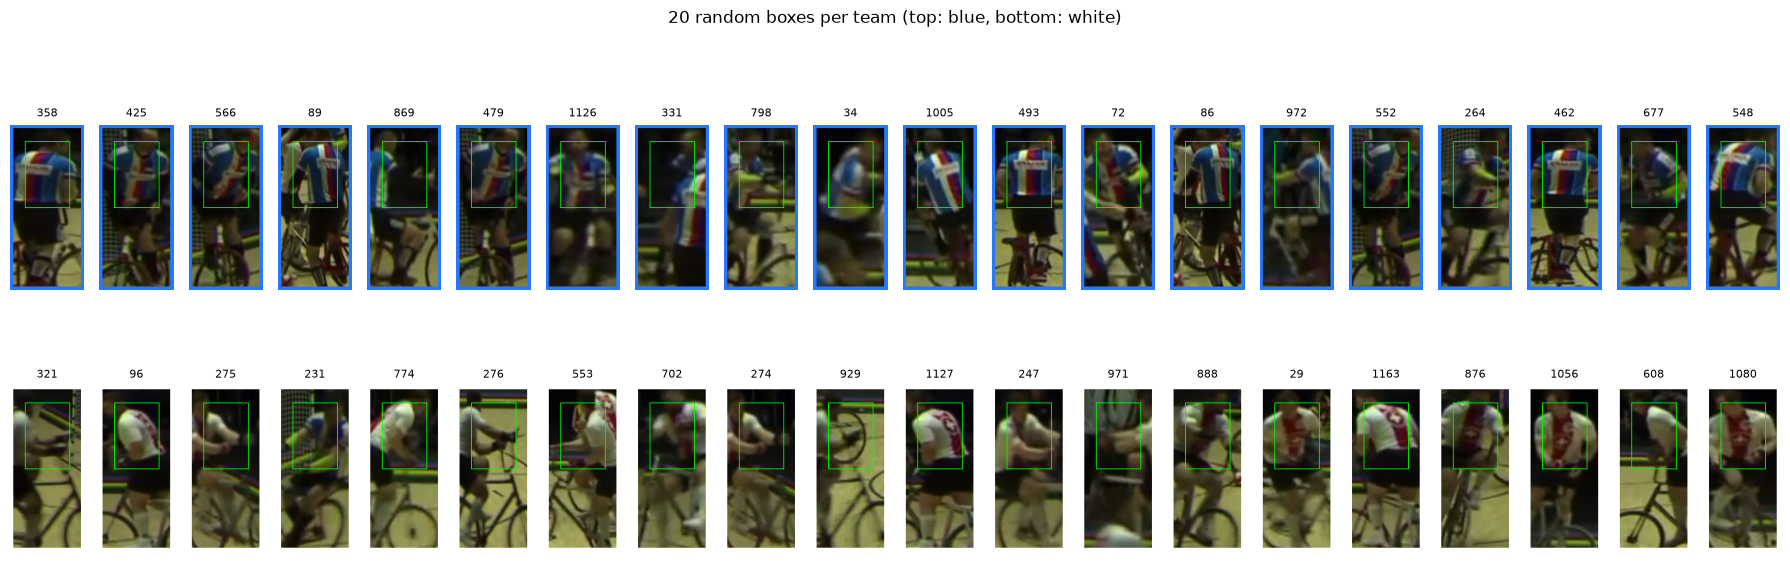

In [5]:
cluster = kmeans_two(np.sqrt(histogram))
players["team"] = np.where(cluster == shirt.blue.groupby(cluster).mean().idxmax(), "blue", "white")
display(shirt.groupby(players.team).mean().round(3))


def frame_image(number):
    video = cv2.VideoCapture(str(VIDEO))
    video.set(cv2.CAP_PROP_POS_FRAMES, number - 1)   # OpenCV counts frames from 0, we count from 1
    return video.read()[1]


size = (90, 200)
shirt_area = ((int(SHIRT_SIDE * size[0]), int(SHIRT_TOP * size[1])), (int((1 - SHIRT_SIDE) * size[0]), int(SHIRT_BOTTOM * size[1])))
fig, axes = plt.subplots(2, 20, figsize=(18, 6.5))
for row_axes, team in zip(axes, TEAM_COLOURS):
    for ax, (_, r) in zip(row_axes, players[players.team == team].sample(20, random_state=SEED).iterrows()):
        crop = cv2.resize(frame_image(r.frame)[int(r.y1):int(r.y2), int(r.x1):int(r.x2)], size)
        cv2.rectangle(crop, *shirt_area, (0, 255, 0), 1)
        cv2.rectangle(crop, (0, 0), (size[0] - 1, size[1] - 1), TEAM_COLOURS[team], 6)
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(r.frame, fontsize=8)
        ax.axis("off")
fig.suptitle("20 random boxes per team (top: blue, bottom: white)")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "team_samples.png", dpi=110)
plt.show()

**Findings:** the two clusters' average shirts match the two kits. Of the 40 crops, 1 is clearly wrong (231, white row: a blue rider at the dark left end). In the other 39 the shirt is either clearly the right kit or too dark or hidden to judge (blue row 869, 972; white row 321, 276, 929, 971).

### 4b. Frames that don't split 2 v 2

How many contain a duplicate; one frame that splits, next to three that don't.

74 of 891 four-box frames do not split 2 v 2; 22 of them contain a duplicate box
the others: [109, 210, 211, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 244, 245, 246, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 631, 632, 714, 715, 716, 717, 718, 719, 799, 800, 1021, 1023, 1024, 1025, 1026, 1027]


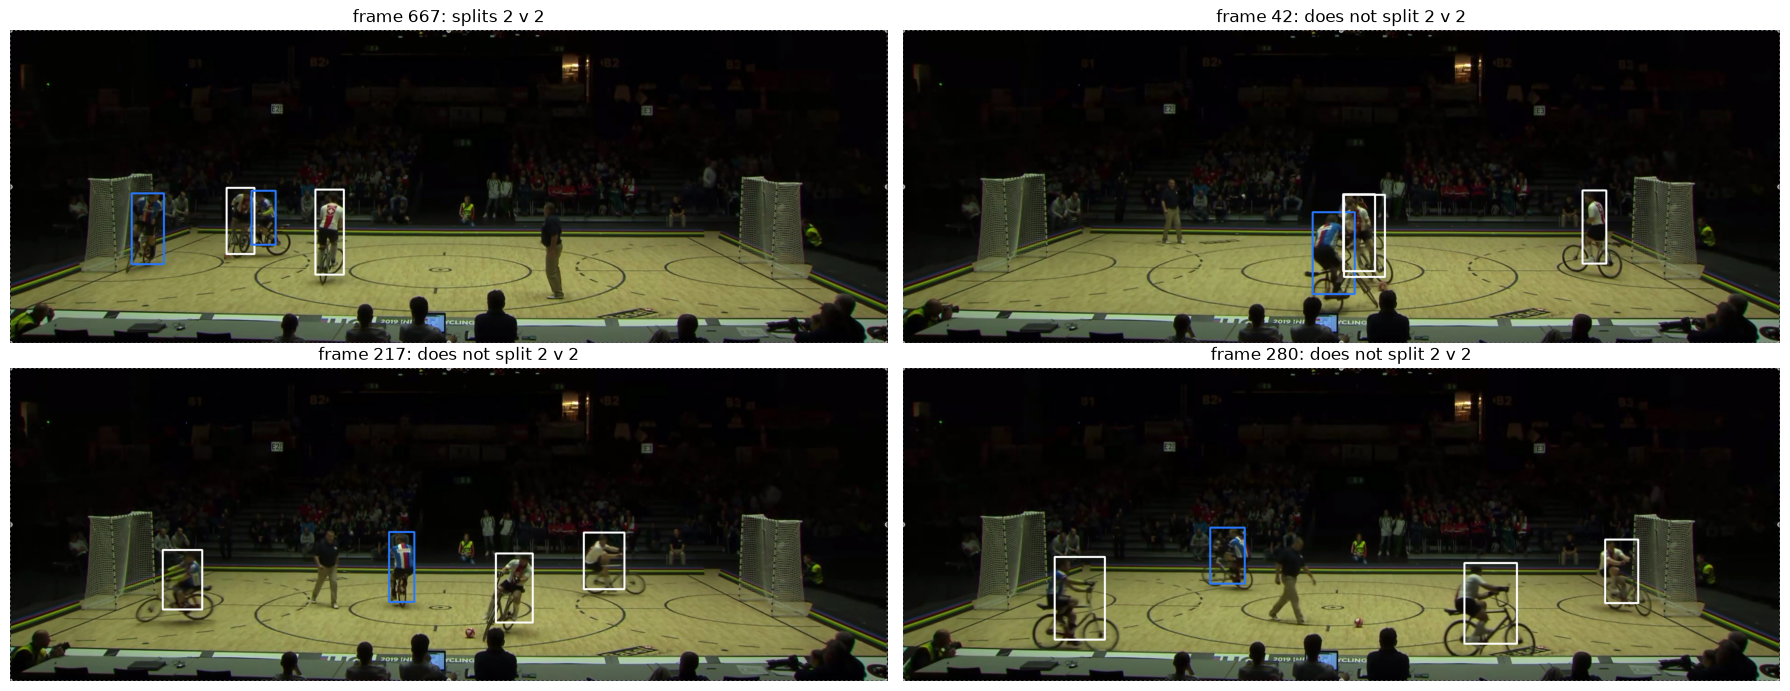

In [6]:
def draw_teams(frame):
    image = frame_image(frame)
    for _, r in players[players.frame == frame].iterrows():
        cv2.rectangle(image, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), TEAM_COLOURS[r.team], 6)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


blues = (players.team == "blue").groupby(players.frame).sum()
four = counts.index[counts == 4]
not_split = four[blues[four] != 2]
print(f"{len(not_split)} of {len(four)} four-box frames do not split 2 v 2; {duplicates[not_split].sum()} of them contain a duplicate box")
print("the others:", [f for f in not_split if not duplicates[f]])

split = four[blues[four] == 2]
examples = [split[len(split) // 2], *not_split[:: len(not_split) // 3][:3]]   # one from the middle of the clip, three spread out
fig, axes = plt.subplots(2, 2, figsize=(18, 7))
for ax, frame in zip(axes.flat, examples):
    ax.imshow(draw_teams(frame))
    ax.set_title(f"frame {frame}: {'splits 2 v 2' if frame not in not_split else 'does not split 2 v 2'}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "team_frames.png", dpi=110)
plt.show()

**Findings:** 74 of 891 four-box frames don't split 2 v 2; 22 contain a duplicate (frame 42 above: two boxes on one rider). The other 52 (printed) come in runs of 1 to 18 frames; by eye (one frame per run), three kinds:
- **Colour mistakes, 41 frames:** a blue rider by the dark left goal put in the white team (210–225, 244–246, 268–285, 714–719; frames 217 and 280 above).
- **Loose double boxes, 3 frames:** a looser second box, or one box over two riders, which the IoU 0.5 check misses (109, 631–632).
- **The referee inside a player box, 8 frames** (799–800, 1021, 1023–1027).

**Conclusions:** only 41 of the 74 are colour mistakes, all at the dark left goal; the other 33 come from the detector (notebook 05, hypotheses 6 and 7). Tracking with a majority vote per rider could fix the colour runs.

## 5. Hand-off: `models/teams.csv`

One row per player box of `detections.csv`, in the same order: `frame`, `x1, y1, x2, y2`, `team` (blue or white). The app joins it on frame and box.

In [7]:
players[["frame", *XY, "team"]].to_csv(OUTPUT, index=False)
print(f"{len(players)} rows written to {OUTPUT.relative_to(ROOT)}")

4659 rows written to models/teams.csv


## Limits

- **One decision per box per frame:** without tracking, a rider can flip team for a few frames.
- **Similar kits** would be hard to separate on colour; the white and dark limits were only checked on this clip.
- **Detection mistakes carry over:** a missed or doubled rider, or a boxed referee, becomes a missing or extra dot.